In [8]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Connessione al database
db_path = '../data/document_analysis.db'
conn = sqlite3.connect(db_path)

print("--- STATISTICHE GENERALI ---")
# Conteggio documenti e triplette
n_docs = pd.read_sql_query("SELECT COUNT(*) FROM documents", conn).iloc[0,0]
n_triples = pd.read_sql_query("SELECT COUNT(*) FROM rdf_triples", conn).iloc[0,0]
print(f"Documenti totali: {n_docs}")
print(f"Relazioni (triplette) estratte: {n_triples}")

print("\n--- TOP 10 PERSONAGGI/ENTITÀ (Per la RQ dei Broker) ---")
# Chi sono i più citati? (Sia come attori che come bersagli)
query_entities = """
SELECT entity, COUNT(*) as frequenza FROM (
    SELECT actor as entity FROM rdf_triples
    UNION ALL
    SELECT target as entity FROM rdf_triples
) GROUP BY entity ORDER BY frequenza DESC LIMIT 10
"""
top_entities = pd.read_sql_query(query_entities, conn)
print(top_entities)

print("\n--- DISTRIBUZIONE TEMPORALE (Per la RQ Evoluzione) ---")
# Vediamo se i timestamp sono utilizzabili
query_time = "SELECT timestamp FROM rdf_triples WHERE timestamp IS NOT NULL"
df_time = pd.read_sql_query(query_time, conn)
# Nota: potrebbe servire pulizia sui dati temporali qui
print(f"Relazioni con data certa: {len(df_time)}")

conn.close()

--- STATISTICHE GENERALI ---
Documenti totali: 25232
Relazioni (triplette) estratte: 107030

--- TOP 10 PERSONAGGI/ENTITÀ (Per la RQ dei Broker) ---
              entity  frequenza
0    Jeffrey Epstein      27590
1   unknown person A       8335
2       Donald Trump       3813
3    Alan Dershowitz       1860
4     Edward Snowden       1843
5         Ehud Barak       1686
6   unknown person B       1347
7         Jeffrey E.       1299
8  Ghislaine Maxwell       1289
9       Steve Bannon       1244

--- DISTRIBUZIONE TEMPORALE (Per la RQ Evoluzione) ---
Relazioni con data certa: 61481


In [9]:
import sqlite3
import pandas as pd

# 1. Connessione
db_path = '../data/document_analysis.db'
conn = sqlite3.connect(db_path)

# 2. Carichiamo la tabella degli alias (la nostra "stele di rosetta")
aliases_df = pd.read_sql_query("SELECT original_name, canonical_name FROM entity_aliases", conn)
# Creiamo un dizionario per una sostituzione velocissima: { 'Jeffrey E.': 'Jeffrey Epstein', ... }
alias_map = dict(zip(aliases_df['original_name'], aliases_df['canonical_name']))

# 3. Carichiamo le triplette
triples_df = pd.read_sql_query("SELECT actor, action, target, timestamp FROM rdf_triples", conn)

# 4. Funzione di pulizia: se il nome è nella mappa degli alias lo cambiamo, altrimenti lo teniamo
def clean_entity(name):
    return alias_map.get(name, name)

# Applichiamo la pulizia ad attori e bersagli
triples_df['actor'] = triples_df['actor'].apply(clean_entity)
triples_df['target'] = triples_df['target'].apply(clean_entity)

print(f"Deduplicazione completata su {len(triples_df)} relazioni.")

# 5. Ricalcoliamo la Top 10 PULITA
all_entities = pd.concat([triples_df['actor'], triples_df['target']])
top_10_clean = all_entities.value_counts().head(10)

print("\n--- NUOVA TOP 10 (Deduplicata) ---")
print(top_10_clean)

conn.close()

Deduplicazione completata su 107030 relazioni.

--- NUOVA TOP 10 (Deduplicata) ---
Jeffrey Epstein       29345
unknown person A       8335
Donald Trump           4082
Alan M. Dershowitz     2082
Edward Snowden         1900
Ehud Barak             1773
unknown person B       1347
Steve Bannon           1301
Ghislaine Maxwell      1294
Bill Clinton           1166
Name: count, dtype: int64


In [10]:
print(triples_df['timestamp'].dropna().unique()[:10])

['1989' '1997-04-08' '1991-11' '1995' '2004-09-08' '2005-03-15' '2005'
 '2005-05' '2008-06' '2016-01']


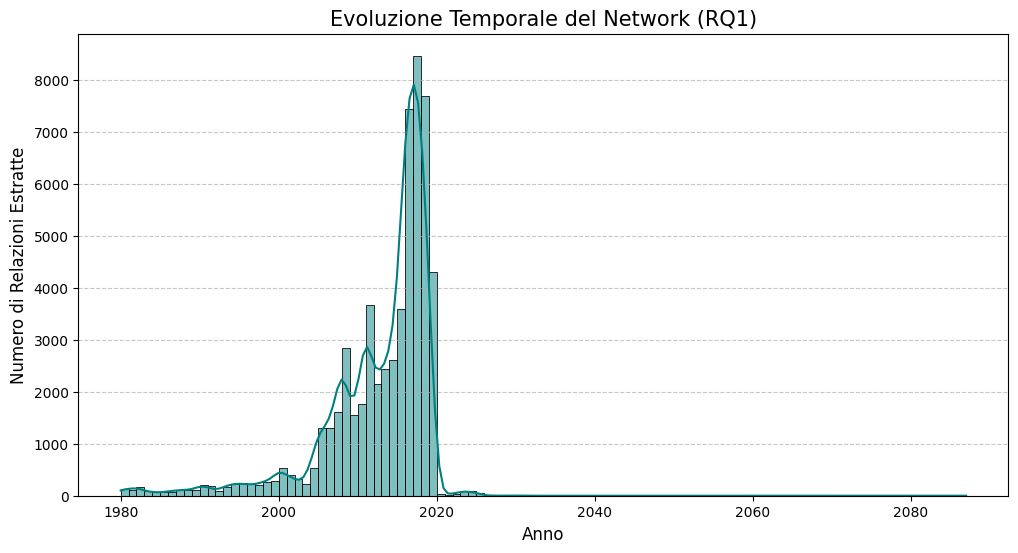

Relazioni totali analizzabili nel tempo: 58187


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Estraiamo l'anno (prendiamo i primi 4 caratteri di ogni stringa non nulla)
triples_df['year'] = triples_df['timestamp'].str.slice(0, 4)

# 2. Convertiamo in numerico (gestendo eventuali errori con NaN)
triples_df['year'] = pd.to_numeric(triples_df['year'], errors='coerce')

# 3. Filtriamo gli anni ragionevoli (es. dal 1980 in poi) per evitare outlier/errori di OCR
triples_df_filtered = triples_df[triples_df['year'] >= 1980]

# 4. Creazione del grafico della densità delle relazioni
plt.figure(figsize=(12, 6))
sns.histplot(triples_df_filtered['year'], bins=int(triples_df_filtered['year'].max() - triples_df_filtered['year'].min()), kde=True, color='teal')

plt.title('Evoluzione Temporale del Network (RQ1)', fontsize=15)
plt.xlabel('Anno', fontsize=12)
plt.ylabel('Numero di Relazioni Estratte', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print(f"Relazioni totali analizzabili nel tempo: {len(triples_df_filtered)}")

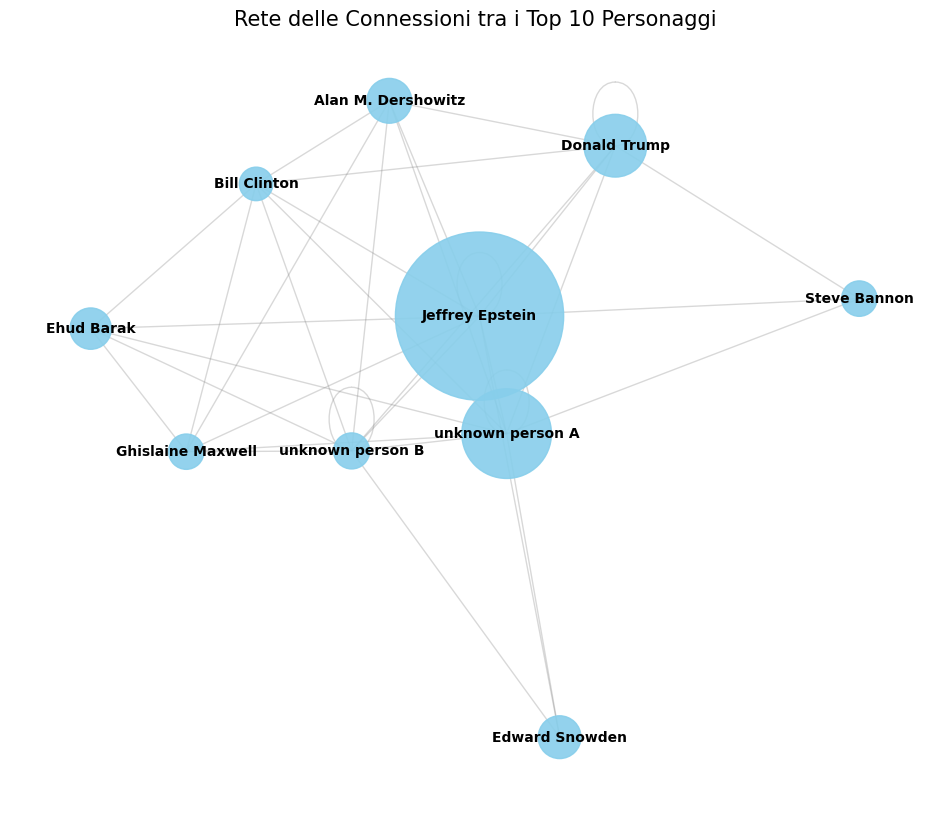

Il grafo visualizzato contiene 10 nodi e 35 archi.


In [12]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Filtriamo il DataFrame per includere solo i Top 10 personaggi (già deduplicati)
# Usiamo i nomi che abbiamo trovato nella "Top 10 Clean" di prima
top_entities = top_10_clean.index.tolist()

# Prendiamo solo le relazioni dove SIA l'actor SIA il target sono nella Top 10
# (così il grafo è leggibile e non una nuvola confusa)
df_graph = triples_df[
    (triples_df['actor'].isin(top_entities)) & 
    (triples_df['target'].isin(top_entities))
]

# 2. Creiamo l'oggetto Grafo
G = nx.from_pandas_edgelist(df_graph, source='actor', target='target', create_using=nx.Graph())

# 3. Disegniamo!
plt.figure(figsize=(12, 10))

# Layout: posiziona i nodi in modo che non si sovrappongano troppo
pos = nx.spring_layout(G, k=0.5, seed=42)

# Disegniamo i nodi pesandoli (più sono citati, più il pallino è grande)
node_sizes = [top_10_clean[node] * 0.5 for node in G.nodes()]

nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color='skyblue', alpha=0.9)
nx.draw_networkx_edges(G, pos, width=1.0, alpha=0.3, edge_color='gray')
nx.draw_networkx_labels(G, pos, font_size=10, font_family='sans-serif', font_weight='bold')

plt.title("Rete delle Connessioni tra i Top 10 Personaggi", fontsize=15)
plt.axis('off') # Nascondiamo gli assi del grafico
plt.show()

print(f"Il grafo visualizzato contiene {G.number_of_nodes()} nodi e {G.number_of_edges()} archi.")

In [13]:
import sqlite3
import pandas as pd
import networkx as nx

# 1. Connessione e caricamento dati puliti
conn = sqlite3.connect('../data/document_analysis.db')

# Carichiamo le triplette e i documenti (per le categorie)
triples = pd.read_sql_query("SELECT actor, target, timestamp FROM rdf_triples", conn)
docs = pd.read_sql_query("SELECT category, paragraph_summary FROM documents", conn)

# --- GIUSTIFICAZIONE RQ2 (Broker & Unknowns) ---
# Creiamo il grafo per calcolare chi "comanda" davvero i flussi
G = nx.from_pandas_edgelist(triples, source='actor', target='target')
betweenness = nx.betweenness_centrality(G, k=1000) # k velocizza il calcolo su grandi reti
df_brokers = pd.DataFrame(betweenness.items(), columns=['Entity', 'Brokerage_Score']).sort_values(by='Brokerage_Score', ascending=False)

print("TOP BROKERS (Giustifica RQ2):")
print(df_brokers.head(10)) 
# Se vedi "Unknown" qui, la RQ2 è ufficialmente giustificata.

# --- GIUSTIFICAZIONE RQ3 (Topologia vs Semantica) ---
# Vediamo come sono distribuiti i documenti per categoria originale
print("\nDISTRIBUZIONE CATEGORIE LLM (Giustifica RQ3):")
print(docs['category'].value_counts())
# Se le categorie sono sbilanciate (es. molto 'Legal'), ha senso vedere se la rete lo riflette.

# --- GIUSTIFICAZIONE RQ1 (Evoluzione Temporale) ---
triples['year'] = triples['timestamp'].str.slice(0, 4)
temp_dist = triples['year'].value_counts().sort_index()
print("\nRELAZIONI PER ANNO (Giustifica RQ1):")
print(temp_dist.tail(10)) # Vediamo gli ultimi anni disponibili

conn.close()

TOP BROKERS (Giustifica RQ2):
                 Entity  Brokerage_Score
28600  unknown person A         0.203752
0       Jeffrey Epstein         0.194177
6          Donald Trump         0.064369
11      Alan Dershowitz         0.024403
688        Barack Obama         0.023461
5295     Edward Snowden         0.019230
607          Ehud Barak         0.018018
1609      United States         0.015583
28706  unknown person B         0.014881
93         Bill Clinton         0.008719

DISTRIBUZIONE CATEGORIE LLM (Giustifica RQ3):
category
email                   6114
other                   5053
report                  3827
book_excerpt            2886
media_article           1935
transcript              1192
financial_document      1187
court_filing             764
mixed_document           739
memorandum               485
public record            387
letter                   264
public_record            255
photo_caption             65
legal_document            32
legal_notice              13

In [14]:
import re

# Funzione per cercare 4 cifre consecutive (l'anno) in qualsiasi parte della stringa
def extract_year(text):
    if pd.isna(text): return None
    match = re.search(r'\b(19|20)\d{2}\b', str(text))
    return match.group(0) if match else None

# Applichiamo la pulizia
triples['clean_year'] = triples['timestamp'].apply(extract_year)

print("DISTRIBUZIONE ANNI REALI (Per RQ1):")
print(triples['clean_year'].value_counts().sort_index().tail(15))

DISTRIBUZIONE ANNI REALI (Per RQ1):
clean_year
2018    7690
2019    4312
2020      39
2021      11
2022      34
2023      82
2024      84
2025      59
2026       4
2027       2
2028       1
2030       6
2031       1
2040       2
2087       1
Name: count, dtype: int64


/var/folders/dn/wvrwwyms14g86kr68lrr5y_00000gn/T/ipykernel_32183/3306406750.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=triples_clean.sort_values('clean_year'), x='clean_year', palette='viridis')


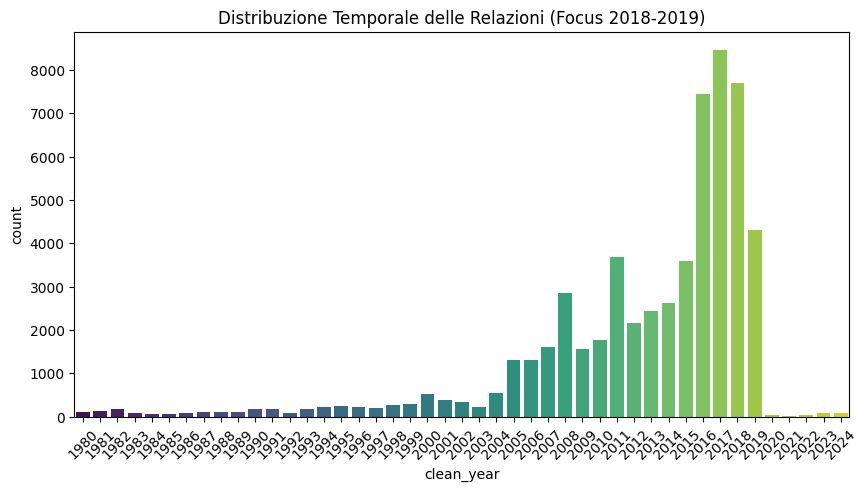

In [16]:
# Teniamo solo gli anni tra il 1990 e il 2024 (quelli sensati)
triples_clean = triples[triples['clean_year'].astype(float).between(1980, 2024)]

# Ora facciamo il grafico definitivo
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
sns.countplot(data=triples_clean.sort_values('clean_year'), x='clean_year', palette='viridis')
plt.xticks(rotation=45)
plt.title("Distribuzione Temporale delle Relazioni (Focus 2018-2019)")
plt.show()